# Exploratory Data Analysis.

---

## Importing Libraies:

In [1]:
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

## Importing Dataset:

In [2]:
data = pd.read_csv("email.csv")

In [3]:
data.sample(10, random_state=69)

,Category,Message
3444,ham,Your board is working fine. The issue of overh...
378,ham,Well there's not a lot of things happening in ...
3330,ham,Sac will score big hundred.he is set batsman:-)
4606,ham,"I need an 8th but I'm off campus atm, could I ..."
2050,ham,How much is blackberry bold2 in nigeria.
131,ham,I'm home.
5419,ham,I'm at bruce &amp; fowler now but I'm in my mo...
1427,ham,Ok...
2908,ham,ALRITE
3200,ham,No de.am seeing in online shop so that i asked.


## Brief Analysis:

In [4]:
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])

Rows: 5572
Columns: 2


In [5]:
print("Duplicated Values:", data.duplicated().sum())

Duplicated Values: 415


In [6]:
print("Missing Values:")
data.isna().sum()

Missing Values:


Category    0
Message     0
dtype: int64

In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Category  5572 non-null   str  
 1   Message   5572 non-null   str  
dtypes: str(2)
memory usage: 542.2 KB


## Detailed Analysis:

### Target Feature: Category

In [8]:
print("Data Split(%):")

(data['Category'].value_counts() / len(data) * 100).round(2)

Data Split(%):


Category
ham     86.59
spam    13.41
Name: count, dtype: float64

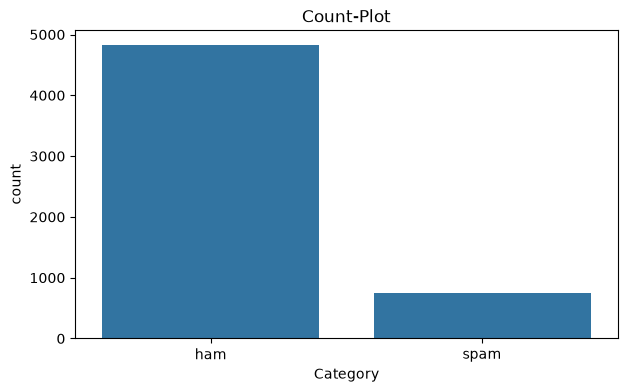

In [9]:
plt.figure(figsize=(7,4))

sns.countplot(data=data, x='Category')
plt.title("Count-Plot")

plt.show()

## Feature Construction:

In [10]:
def build_features(df, col='Message'):
    df = df.copy()                      
    text = df[col].astype(str)

    # --- length features ---
    df['char_len'] = text.str.len()                      
    df['word_count'] = text.str.split().str.len()        

    # --- number features ---
    df['digit_count'] = text.str.count(r'\d')            
    df['has_number'] = (df['digit_count'] > 0).astype(int) 
    df['number_count'] = text.str.count(r'\d+')
    df['has_phone'] = text.str.contains(r'\d{10,}').astype(int)

    # --- link feature ---
    df['has_url'] = text.str.contains(r'http|www\.|\.com|\.co\.uk', case=False).astype(int)

    # --- style features ---
    df['upper_ratio'] = text.str.count(r'[A-Z]') / df['char_len']
    df['special_count'] = text.str.count(r'[^A-Za-z0-9\s]')
    df['exclaim_count'] = text.str.count('!')
    df['has_currency'] = text.str.contains(r'[£$€]').astype(int)

    # --- spam keyword feature ---
    keywords = r'\b(free|txt|stop|text|mobile|reply|claim|prize|cash|150p|urgent|won|nokia|service|msg|contact|win)\b'
    df['keyword_count'] = text.str.lower().str.count(keywords)

    return df

In [11]:
df = build_features(data)

df.drop(columns=['Message'], inplace=True)

# EDA On New Features:

In [12]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 5572
Columns: 13


In [13]:
print("Duplicated Values:", df.duplicated().sum())

Duplicated Values: 1257


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Category       5572 non-null   str    
 1   char_len       5572 non-null   int64  
 2   word_count     5572 non-null   int64  
 3   digit_count    5572 non-null   int64  
 4   has_number     5572 non-null   int64  
 5   number_count   5572 non-null   int64  
 6   has_phone      5572 non-null   int64  
 7   has_url        5572 non-null   int64  
 8   upper_ratio    5572 non-null   float64
 9   special_count  5572 non-null   int64  
 10  exclaim_count  5572 non-null   int64  
 11  has_currency   5572 non-null   int64  
 12  keyword_count  5572 non-null   int64  
dtypes: float64(1), int64(11), str(1)
memory usage: 583.1 KB


### 1. char_len:

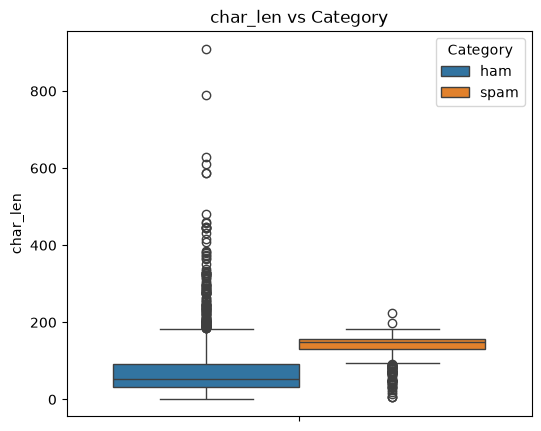

In [15]:
fig = plt.figure(figsize=(6, 5))

sns.boxplot(data=df, y='char_len', hue='Category')
plt.title('char_len vs Category')

plt.show()

### 2. word_count:

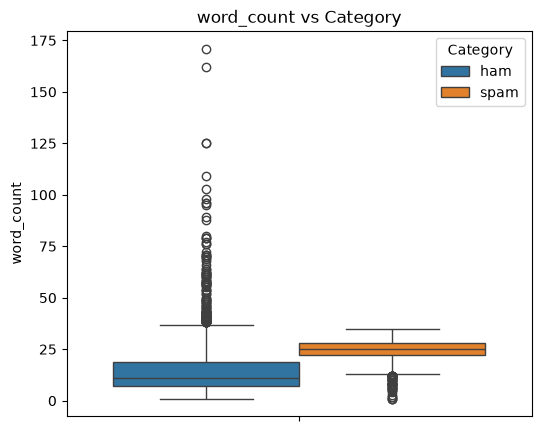

In [16]:
fig = plt.figure(figsize=(6, 5))

sns.boxplot(data=df, y='word_count', hue='Category')
plt.title('word_count vs Category')

plt.show()

### 3. digit_count:

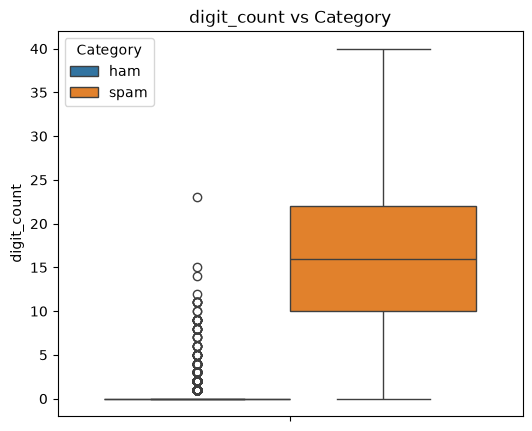

In [17]:
fig = plt.figure(figsize=(6, 5))

sns.boxplot(data=df, y='digit_count', hue='Category')
plt.title('digit_count vs Category')

plt.show()

### 4. has_number:

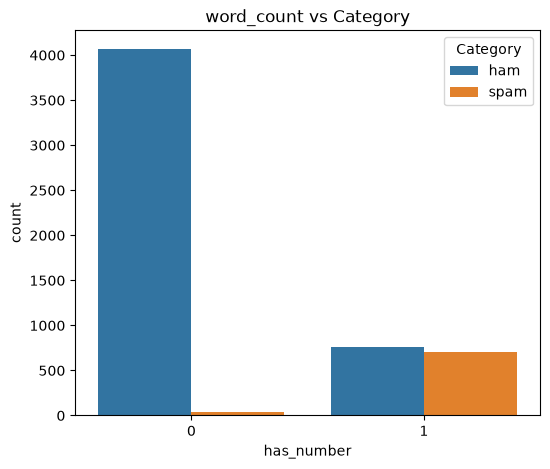

In [18]:
fig = plt.figure(figsize=(6, 5))

sns.countplot(data=df, x='has_number', hue='Category')
plt.title('word_count vs Category')

plt.show()

### 5. number_count:

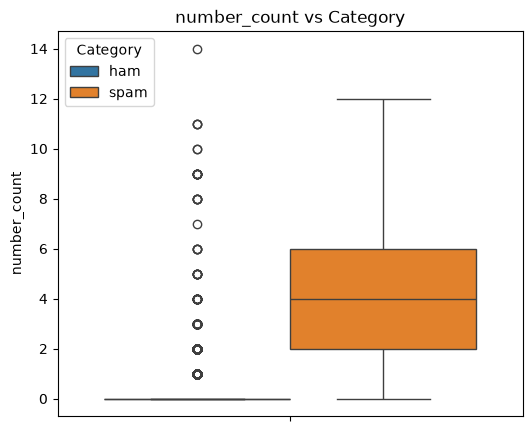

In [19]:
fig = plt.figure(figsize=(6, 5))

sns.boxplot(data=df, y='number_count', hue='Category')
plt.title('number_count vs Category')

plt.show()

### 6. has_phone:

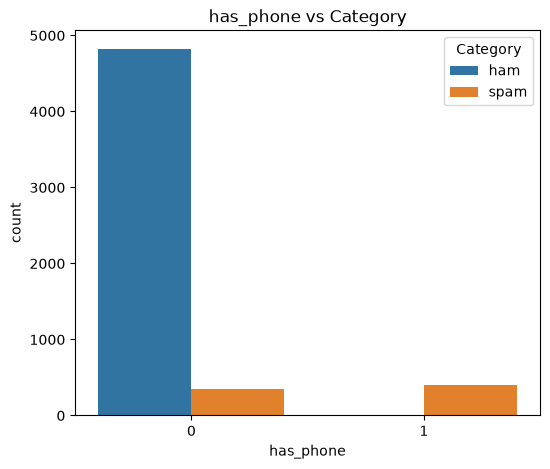

In [20]:
fig = plt.figure(figsize=(6, 5))

sns.countplot(data=df, x='has_phone', hue='Category')
plt.title('has_phone vs Category')

plt.show()

### 7. has_url:

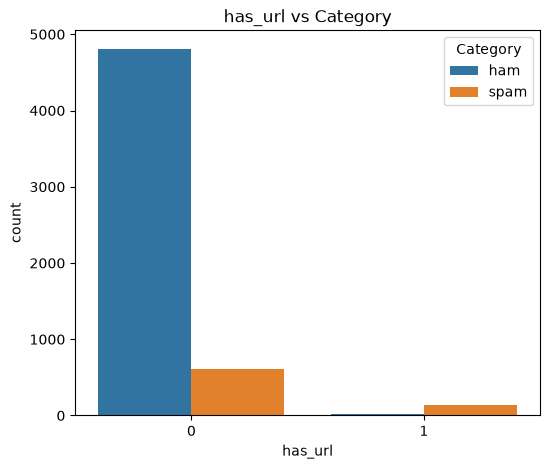

In [21]:
fig = plt.figure(figsize=(6, 5))

sns.countplot(data=df, x='has_url', hue='Category')
plt.title('has_url vs Category')

plt.show()

### 8. upper_ratio:

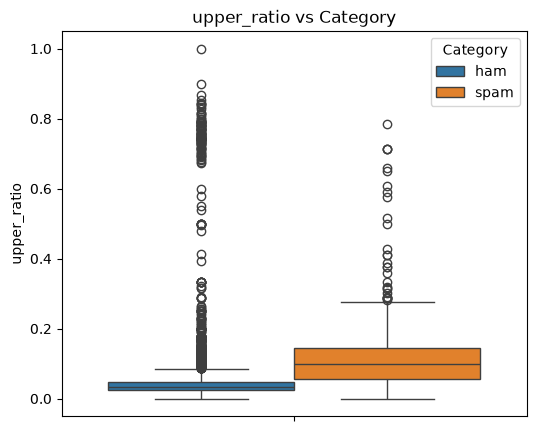

In [22]:
fig = plt.figure(figsize=(6, 5))

sns.boxplot(data=df, y='upper_ratio', hue='Category')
plt.title('upper_ratio vs Category')

plt.show()

### 9. speical_count:

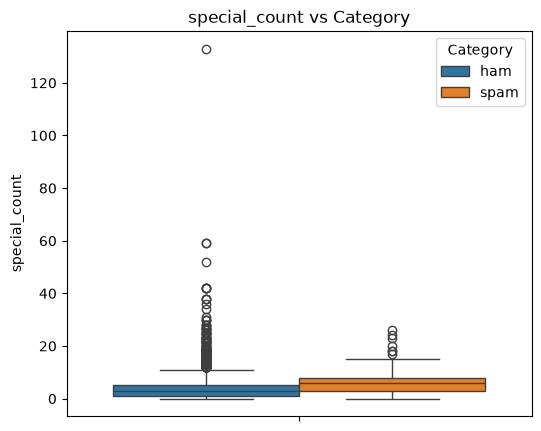

In [23]:
fig = plt.figure(figsize=(6, 5))

sns.boxplot(data=df, y='special_count', hue='Category')
plt.title('special_count vs Category')

plt.show()

### 10. exclaim_count:

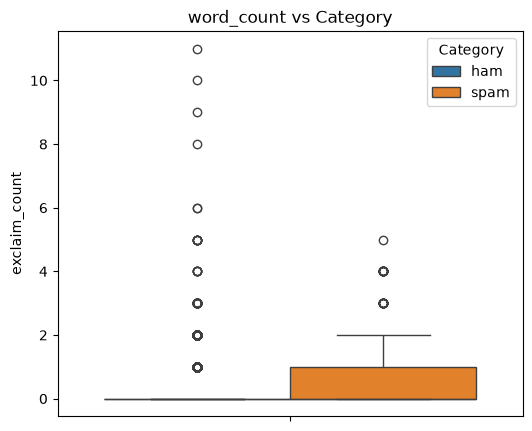

In [24]:
fig = plt.figure(figsize=(6, 5))

sns.boxplot(data=df, y='exclaim_count', hue='Category')
plt.title('word_count vs Category')

plt.show()

### 11. word_count:

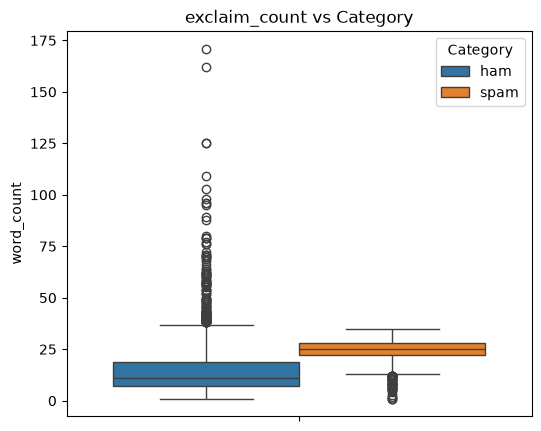

In [25]:
fig = plt.figure(figsize=(6, 5))

sns.boxplot(data=df, y='word_count', hue='Category')
plt.title('exclaim_count vs Category')

plt.show()

### 12. has_currency:

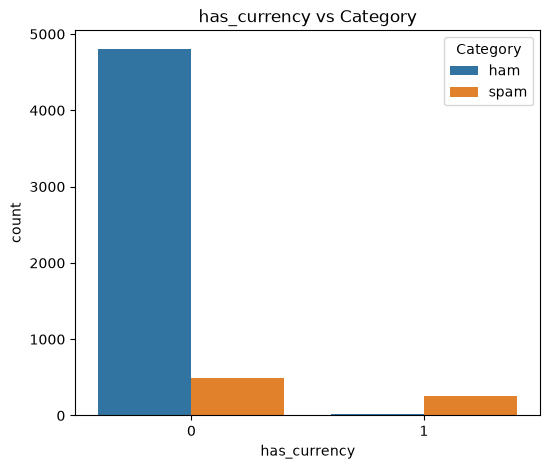

In [26]:
fig = plt.figure(figsize=(6, 5))

sns.countplot(data=df, x='has_currency', hue='Category')
plt.title('has_currency vs Category')

plt.show()

### 13. keyword_count:

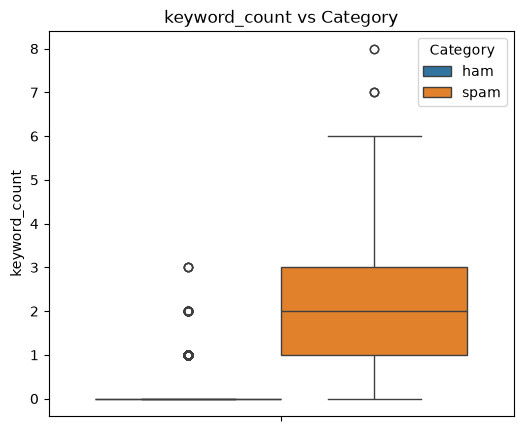

In [27]:
fig = plt.figure(figsize=(6, 5))

sns.boxplot(data=df, y='keyword_count', hue='Category')
plt.title('keyword_count vs Category')

plt.show()

---

# Summary:

- **Target Feature:**

| Feature | Feature Engineering |
| - | - |
| Category | Label-Encoding |

- *Remove Duplicated Values* from *raw dataset*.

- **Feature Construction:**

|word_count | digit_count | has_number | number_count| has_phone | has_url | upper_ratio | special_count | exclaim_count | has_currency | keyword_count |
| - | - | - | - | - | - | - | - | - | - | - |